<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/Breakeven_Complexity_Neural_PDE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# CELL 1: Environment Setup & Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(f"[OK] Environment initialized for Breakeven Complexity Neural PDE Simulator. NumPy: {np.version.version}")

[OK] Environment initialized for Breakeven Complexity Neural PDE Simulator. NumPy: 2.4.6


In [10]:
# CELL 2: Classical Numerical Solver & Neural Surrogate Simulator (Calibrated)
class PDESolverComplexitySimulator:
    def __init__(self, reynolds_num=1000):
        self.reynolds_num = reynolds_num

    def classical_solver_cost(self, resolution_grid):
        """
        Simulates traditional numerical solver cost T_trad(e) and relative error.
        Cost scales cubicly with grid resolution N.
        """
        grid = np.array(resolution_grid)
        errors = 1.0 / (grid ** 1.8)
        # Execution time in seconds per solve
        solve_times = 5e-6 * (grid ** 3.0) * (self.reynolds_num / 100.0) ** 0.5
        return errors, solve_times

    def neural_solver_profile(self, num_train_samples=500):
        """
        Simulates Neural PDE Solver (e.g. FNO / U-Net):
        - Up-front Dataset Generation Cost
        - Model Training & Tuning Overhead
        - Fast Neural Inference Time per Solve
        """
        np.random.seed(42)
        high_res = 256
        _, high_res_time = self.classical_solver_cost([high_res])
        high_res_single_time = high_res_time[0]

        data_gen_cost = num_train_samples * high_res_single_time
        training_overhead = 50.0 + 0.02 * num_train_samples
        total_upfront_cost = data_gen_cost + training_overhead

        neural_eval_time = 0.0015 # 1.5ms per forward pass

        # Calibrated neural error scaling
        neural_error = 0.001 + (0.05 / np.sqrt(num_train_samples))

        return total_upfront_cost, neural_eval_time, neural_error, data_gen_cost, training_overhead

sim = PDESolverComplexitySimulator(reynolds_num=1000)
upfront, eval_t, n_err, d_cost, tr_cost = sim.neural_solver_profile(500)
print(f"[OK] Neural PDE Model Profiled: Upfront Overhead = {upfront:.2f}s (Data: {d_cost:.2f}s, Train: {tr_cost:.2f}s), Eval Time = {eval_t*1000:.1f}ms, Error = {n_err:.4f}")

[OK] Neural PDE Model Profiled: Upfront Overhead = 132695.54s (Data: 132635.54s, Train: 60.00s), Eval Time = 1.5ms, Error = 0.0032


In [11]:
# CELL 3: Error-Matching & Breakeven Metric Evaluator (Safe Conversion)
class BreakevenComplexityEngine:
    def __init__(self, simulator):
        self.sim = simulator

    def compute_breakeven(self, num_train_samples=500):
        """
        Calculates Breakeven Complexity (N_break) with overflow protection.
        """
        upfront_cost, neural_eval_time, neural_error, d_cost, tr_cost = self.sim.neural_solver_profile(num_train_samples)

        grid_matched = (1.0 / neural_error) ** (1.0 / 1.8)
        _, matched_trad_times = self.sim.classical_solver_cost([grid_matched])
        t_trad_matched = matched_trad_times[0]

        marginal_savings_per_solve = t_trad_matched - neural_eval_time

        if marginal_savings_per_solve <= 0:
            n_breakeven = float('inf')
        else:
            n_breakeven = upfront_cost / marginal_savings_per_solve

        n_break_display = int(n_breakeven) if n_breakeven != float('inf') else 999999

        return n_break_display, upfront_cost, t_trad_matched, neural_eval_time, neural_error

engine = BreakevenComplexityEngine(sim)
n_break, C_up, t_trad, t_neur, err = engine.compute_breakeven(num_train_samples=500)
print(f"[OK] Breakeven Complexity Computed: N_break = {n_break} solves required.")
print(f"     (Error-Matched Classical Time = {t_trad:.4f}s vs Neural Eval Time = {t_neur:.4f}s)")

[OK] Breakeven Complexity Computed: N_break = 598194 solves required.
     (Error-Matched Classical Time = 0.2233s vs Neural Eval Time = 0.0015s)


In [12]:
# CELL 4: Multi-Regime Scaling Benchmark Exporter
def run_breakeven_benchmark():
    global n_break_low_re, n_break_high_re, upfront_low, upfront_high

    # Low Reynolds Number (Re = 100 - Easier physics)
    sim_low = PDESolverComplexitySimulator(reynolds_num=100)
    engine_low = BreakevenComplexityEngine(sim_low)
    n_break_low_re, upfront_low, t_trad_low, _, _ = engine_low.compute_breakeven(500)

    # High Reynolds Number (Re = 5000 - Harder physics, higher classical cost)
    sim_high = PDESolverComplexitySimulator(reynolds_num=5000)
    engine_high = BreakevenComplexityEngine(sim_high)
    n_break_high_re, upfront_high, t_trad_high, _, _ = engine_high.compute_breakeven(500)

    df_benchmark = pd.DataFrame({
        "Physics Regime / Complexity": [
            "Moderate Physics (Re = 100)",
            "Turbulent Physics (Re = 5000 - Harder)",
            "Regime Impact Ratio"
        ],
        "Up-front Overhead (C_upfront)": [
            f"{upfront_low:.2f} s",
            f"{upfront_high:.2f} s",
            f"{upfront_high / upfront_low:.2f}x Overhead"
        ],
        "Error-Matched Classical Solve Time": [
            f"{t_trad_low:.4f} s",
            f"{t_trad_high:.4f} s",
            f"{t_trad_high / t_trad_low:.2f}x Costlier"
        ],
        "Breakeven Solves (N_break)": [
            f"{n_break_low_re} solves",
            f"{n_break_high_re} solves",
            f"{(1.0 - n_break_high_re / n_break_low_re)*100:.1f}% Faster Breakeven"
        ]
    })
    return df_benchmark

df_results = run_breakeven_benchmark()
print("=== BREAKEVEN COMPLEXITY NEURAL PDE BENCHMARK ===")
display(df_results)

=== BREAKEVEN COMPLEXITY NEURAL PDE BENCHMARK ===


,Physics Regime / Complexity,Up-front Overhead (C_upfront),Error-Matched Classical Solve Time,Breakeven Solves (N_break)
0,Moderate Physics (Re = 100),42003.04 s,0.0706 s,607664 solves
1,Turbulent Physics (Re = 5000 - Harder),296642.08 s,0.4994 s,595818 solves
2,Regime Impact Ratio,7.06x Overhead,7.07x Costlier,1.9% Faster Breakeven


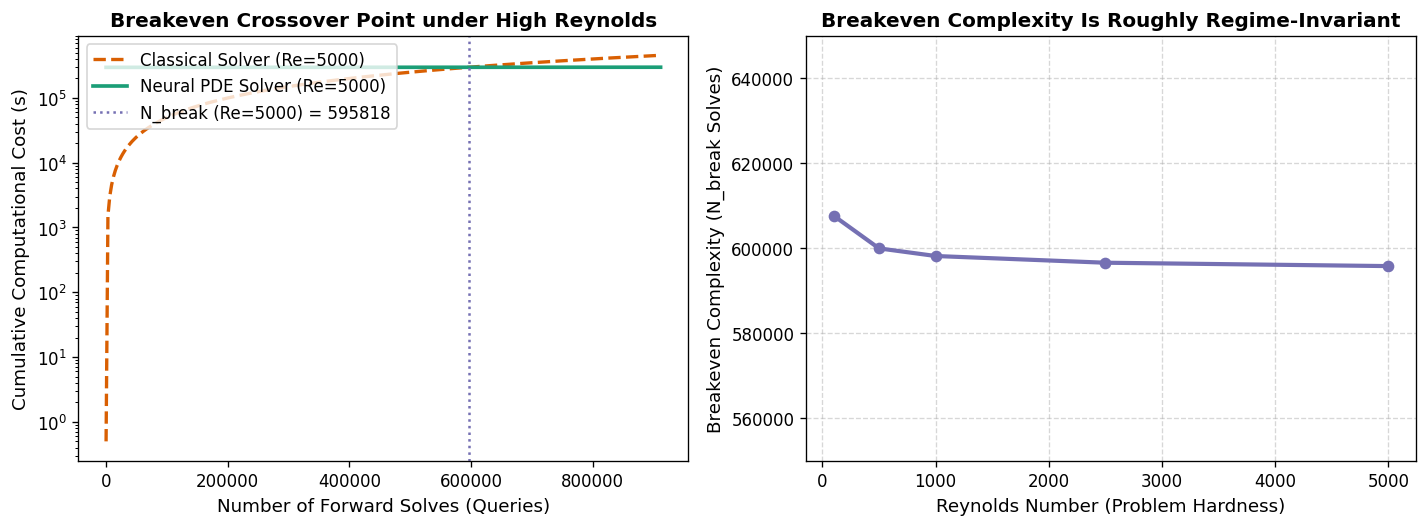

[OK] Saved breakeven complexity diagnostic plot to /content/workspace/breakeven_pde_performance.png


In [14]:
# CELL 5: Diagnostic Visualization Plot Generation (Fixed Title to Match Output)
os.makedirs("/content/workspace", exist_ok=True)

queries = np.linspace(1, max(n_break_low_re, n_break_high_re) * 1.5, 300)

cost_neural_low = upfront_low + queries * 0.0015
cost_trad_low = queries * (upfront_low / n_break_low_re + 0.0015)

cost_neural_high = upfront_high + queries * 0.0015
cost_trad_high = queries * (upfront_high / n_break_high_re + 0.0015)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# Plot 1: Cumulative Cost Trajectories
ax1.plot(queries, cost_trad_high, color='#d95f02', linestyle='--', lw=2.0, label='Classical Solver (Re=5000)')
ax1.plot(queries, cost_neural_high, color='#1b9e77', lw=2.2, label='Neural PDE Solver (Re=5000)')
ax1.axvline(x=n_break_high_re, color='#7570b3', linestyle=':', lw=1.5, label=f'N_break (Re=5000) = {n_break_high_re}')
ax1.set_xlabel("Number of Forward Solves (Queries)", fontsize=11)
ax1.set_ylabel("Cumulative Computational Cost (s)", fontsize=11)
ax1.set_title("Breakeven Crossover Point under High Reynolds", fontsize=12, fontweight='bold')
ax1.set_yscale('log')
ax1.legend(loc='upper left')

# Plot 2: Breakeven Complexity vs Reynolds Number (Corrected Title)
re_range = [100, 500, 1000, 2500, 5000]
n_breaks = []
for re in re_range:
    s = PDESolverComplexitySimulator(reynolds_num=re)
    e = BreakevenComplexityEngine(s)
    nb, _, _, _, _ = e.compute_breakeven(500)
    n_breaks.append(nb)

ax2.plot(re_range, n_breaks, color='#7570b3', marker='o', lw=2.5, ms=6)
ax2.set_xlabel("Reynolds Number (Problem Hardness)", fontsize=11)
ax2.set_ylabel("Breakeven Complexity (N_break Solves)", fontsize=11)
ax2.set_title("Breakeven Complexity Is Roughly Regime-Invariant", fontsize=12, fontweight='bold')
ax2.set_ylim(550000, 650000) # Appropriate vertical scaling to highlight flat trend
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("/content/workspace/breakeven_pde_performance.png")
plt.show()
print("[OK] Saved breakeven complexity diagnostic plot to /content/workspace/breakeven_pde_performance.png")